In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

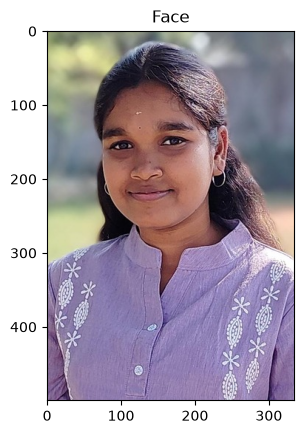

In [2]:
# Load the Face Image
faceImage = cv2.imread('Nivi.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [3]:
faceImage.shape

(500, 335, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(500, 335, 3)

Text(0.5, 1.0, 'glassPNG')

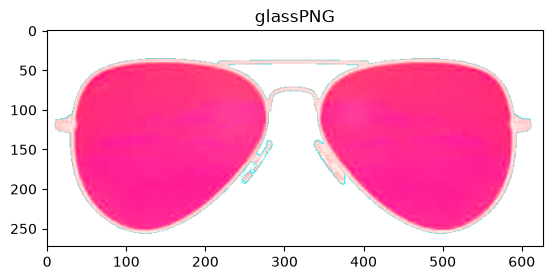

In [12]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glass = cv2.imread('Image-Source-PlusPNG.com.png',-1)
plt.imshow(glass[:,:,::-1]);plt.title("glassPNG")

In [13]:
# Resize the image to fit over the eye region
glass = cv2.resize(glass,(190,50))
print("image Dimension ={}".format(glass.shape))

image Dimension =(50, 190, 4)


In [14]:

# Separate the Color and alpha channels
glassBGR = glass[:,:,0:3]
glassMask1 = glass[:,:,3]

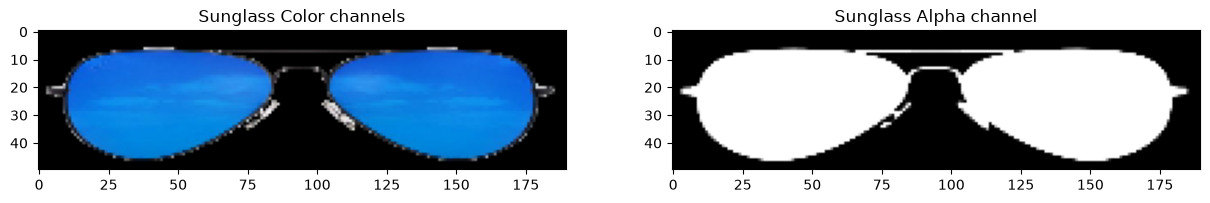

In [15]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

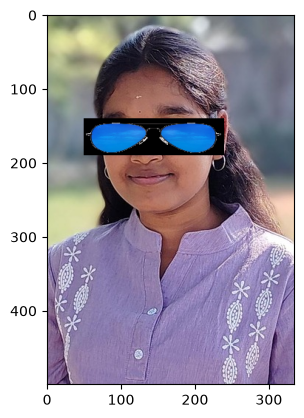

In [39]:

faceWithGlass = faceImage.copy()
faceWithGlass[140:190, 50:240] = glassBGR
plt.imshow(faceWithGlass[...,::-1])

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

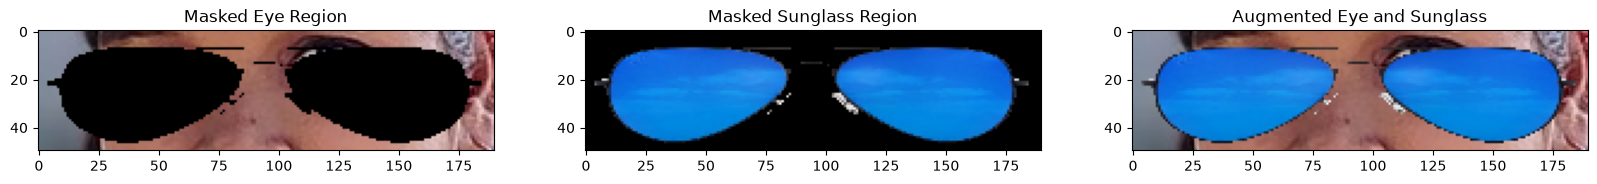

In [40]:
# Make the dimensions of the mask same as the input image.
# Since Face Image is a 3-channel image, we create a 3 channel image for the mask
glassMask = cv2.merge((glassMask1,glassMask1,glassMask1))

# Make the values [0,1] since we are using arithmetic operations
glassMask = np.uint8(glassMask/255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region from the face image
eyeROI= faceWithGlassesArithmetic[140:190, 50:240]

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI,(1-  glassMask ))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR,glassMask)

# Combine the Sunglass in the Eye Region to get the augmented image
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=[20,20])
plt.subplot(131);plt.imshow(maskedEye[...,::-1]);plt.title("Masked Eye Region")
plt.subplot(132);plt.imshow(maskedGlass[...,::-1]);plt.title("Masked Sunglass Region")
plt.subplot(133);plt.imshow(eyeRoiFinal[...,::-1]);plt.title("Augmented Eye and Sunglass")

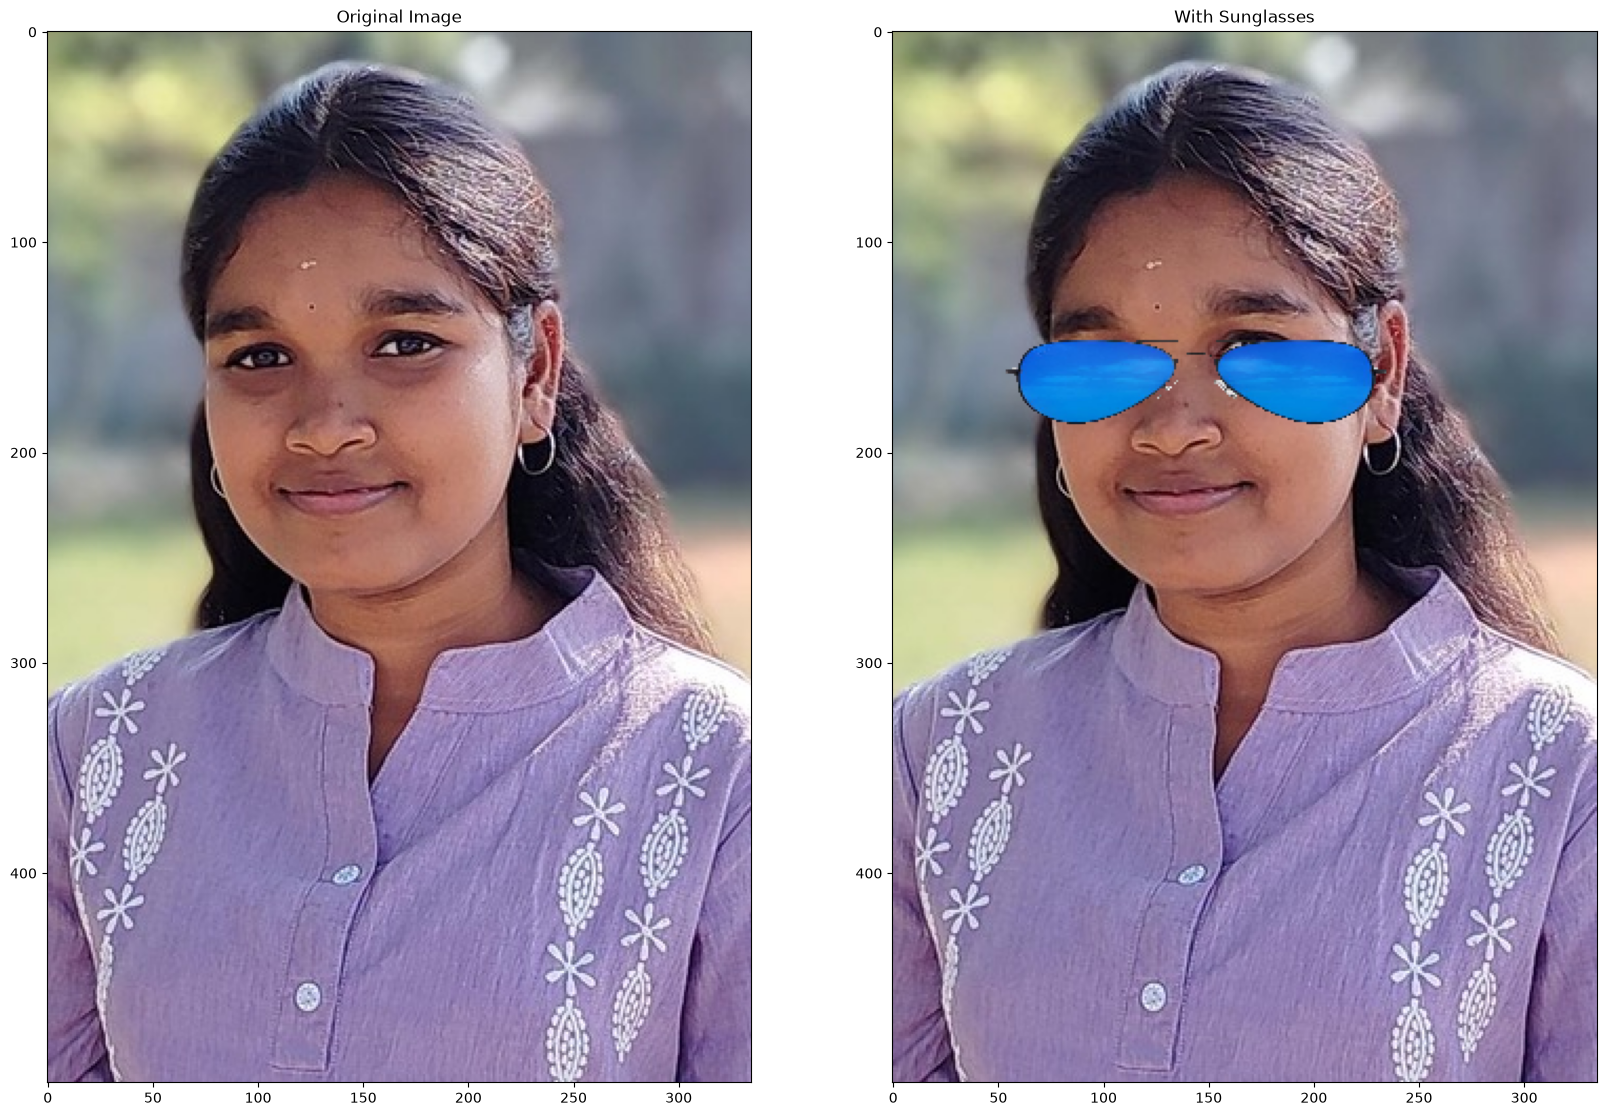

In [41]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[140:190, 50:240]=eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20]);
plt.subplot(121);plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image");
plt.subplot(122);plt.imshow(faceWithGlassesArithmetic[:,:,::-1]);plt.title("With Sunglasses");